# 04 - Comparative Analysis of US and Indian Stocks

## Objective

The objective of this notebook is to compare the historical performance of selected US and Indian companies using various statistical measures and visualizations.

### Companies

#### US Companies
- Apple
- Microsoft
- NVIDIA
- Amazon

#### Indian Companies
- Reliance Industries
- Tata Consultancy Services (TCS)
- HDFC Bank
- Infosys

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")

%matplotlib inline

In [2]:
companies = {
    "Apple": "../data/cleaned/AAPL.csv",
    "Amazon": "../data/cleaned/AMZN.csv",
    "Microsoft": "../data/cleaned/MSFT.csv",
    "NVIDIA": "../data/cleaned/NVDA.csv",
    
    "Reliance": "../data/cleaned/RELIANCE.NS.csv",
    "TCS": "../data/cleaned/TCS.NS.csv",
    "HDFC Bank": "../data/cleaned/HDFCBANK.NS.csv",
    "Infosys": "../data/cleaned/INFY.NS.csv"
}

stock_data = {}

for company, path in companies.items():

    df = pd.read_csv(path, parse_dates=["Date"])
    df = df.sort_values("Date").drop_duplicates(subset=["Date"])
    stock_data[company] = df.reset_index(drop=True)

In [3]:
stock_data['Apple'].head()

,Date,Adj Close,Close,High,Low,Open,Volume,Company
0,2015-01-02,24.171764,27.332500,27.860001,26.837500,27.847500,212818400,AAPL
1,2015-01-05,23.490799,26.562500,27.162500,26.352501,27.072500,257142000,AAPL
2,2015-01-06,23.493011,26.565001,26.857500,26.157499,26.635000,263188400,AAPL
3,2015-01-07,23.822432,26.937500,27.049999,26.674999,26.799999,160423600,AAPL
4,2015-01-08,24.737747,27.972500,28.037500,27.174999,27.307501,237458000,AAPL


## Analysis 1

### How do the closing prices of different companies change over time?

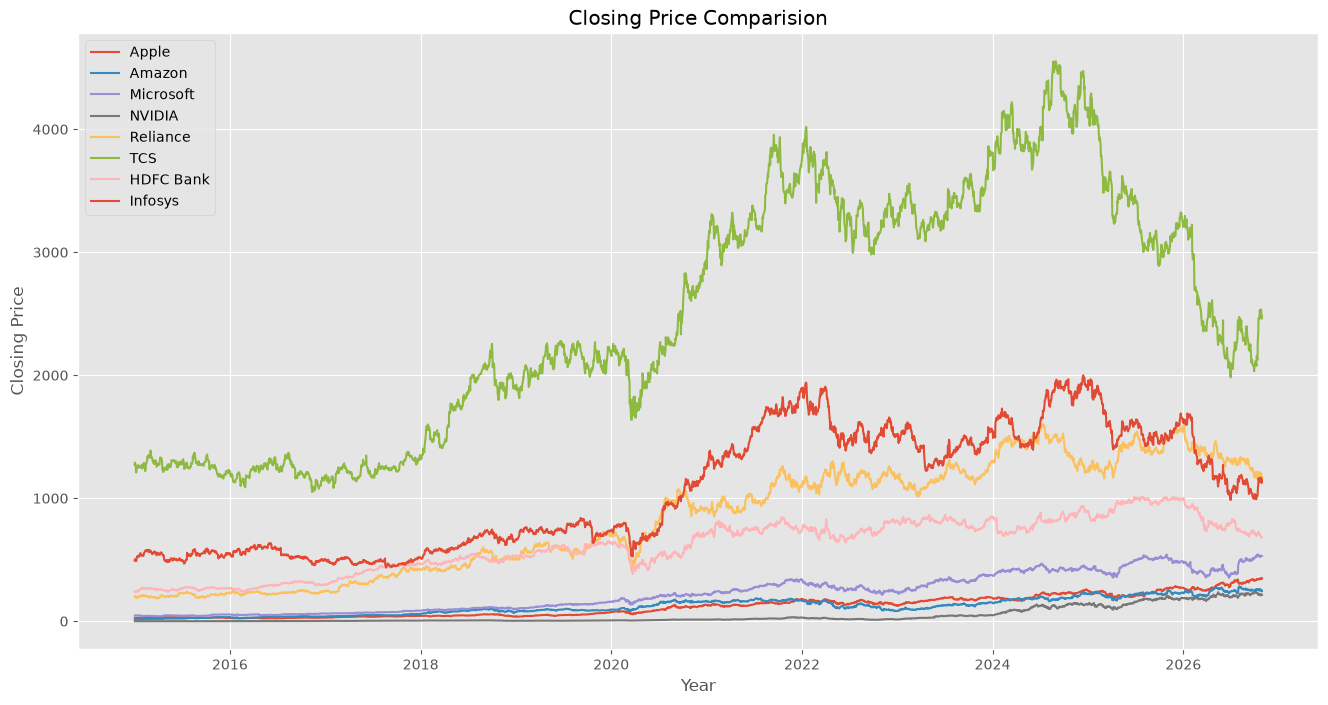

In [4]:
plt.figure(figsize=(16,8))

for company, df in stock_data.items():
    
    plt.plot(
        df["Date"],
        df["Close"],
        label = company
    )

plt.title("Closing Price Comparision")

plt.xlabel("Year")
plt.ylabel("Closing Price")

plt.legend()
plt.show()

In [5]:
normalized_data = {}

for company, df in stock_data.items() :
    
    temp = df.copy()
    temp["Normalized_Close"] = (temp["Close"] / temp["Close"].iloc[0]) * 100
    
    normalized_data[company] = temp   


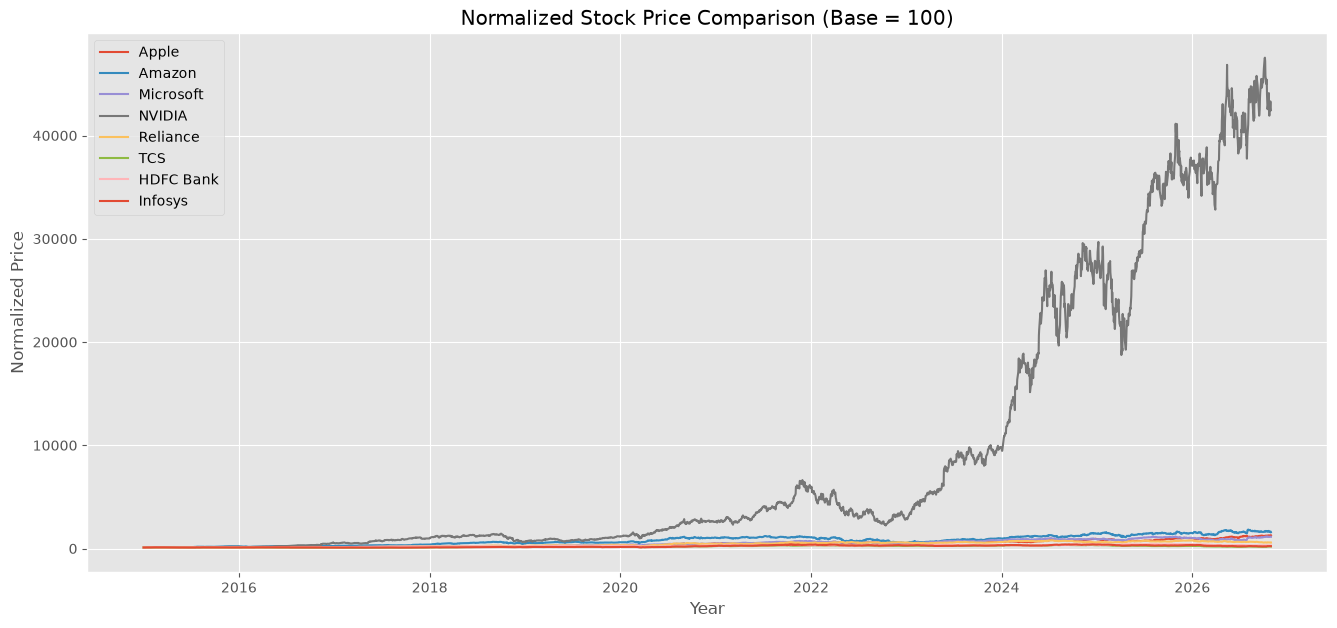

In [6]:
plt.figure(figsize=(16,7))

for company, df in normalized_data.items():

    plt.plot(
        df["Date"],
        df["Normalized_Close"],
        label=company
    )

plt.title("Normalized Stock Price Comparison (Base = 100)")

plt.xlabel("Year")
plt.ylabel("Normalized Price")

plt.legend()

plt.show()

### Observation

Normalizing stock prices allows all companies to start from the same baseline (100), making it easier to compare their relative growth regardless of currency or initial stock price.

## Analysis 2 — Cumulative Returns

Cumulative return measures the percentage change in a stock's closing price over the available period. Unlike raw closing prices, it allows performance to be compared without being distorted by different starting prices or currencies.

**Formula:** `((Last Close / First Close) - 1) × 100`


,Company,Cumulative Return (%)
0,NVIDIA,42356.04
1,Amazon,1480.38
2,Apple,1176.54
3,Microsoft,1033.75
4,Reliance,475.19
5,HDFC Bank,187.09
6,Infosys,132.27
7,TCS,94.69


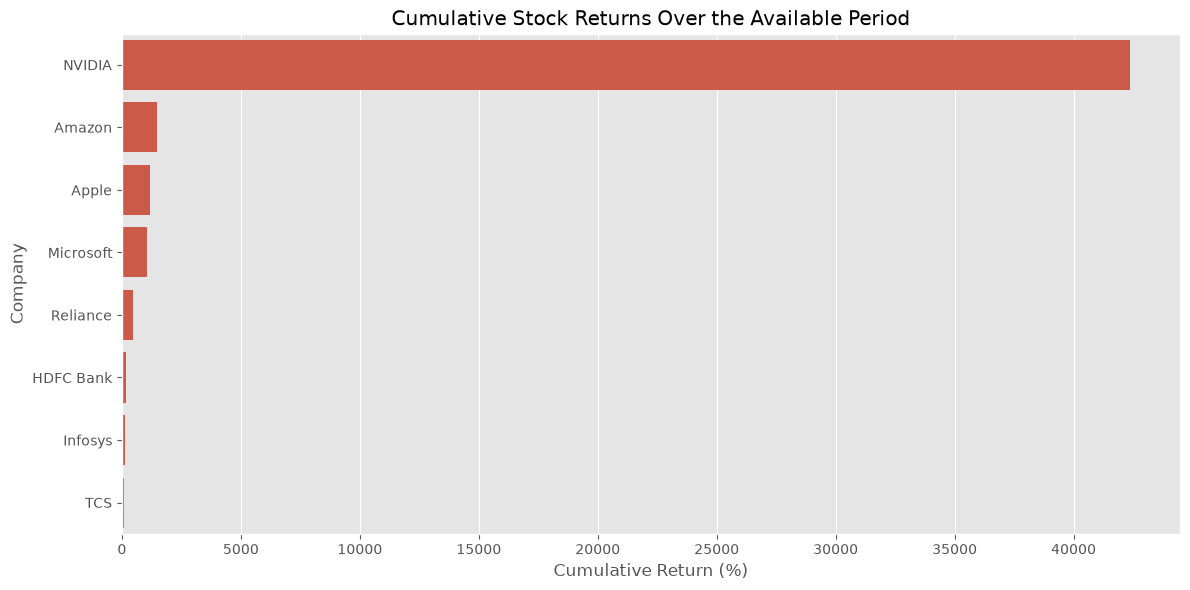

In [7]:
cumulative_returns = {}

for company, df in stock_data.items():
    df = df.sort_values("Date").dropna(subset=["Close"])
    if len(df) < 2 or df["Close"].iloc[0] == 0:
        continue

    cumulative_returns[company] = (
        (df["Close"].iloc[-1] / df["Close"].iloc[0]) - 1
    ) * 100

cumulative_returns_df = (
    pd.DataFrame({
        "Company": list(cumulative_returns.keys()),
        "Cumulative Return (%)": list(cumulative_returns.values())
    })
    .sort_values("Cumulative Return (%)", ascending=False)
    .reset_index(drop=True)
)

display(cumulative_returns_df.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=cumulative_returns_df,
    x="Cumulative Return (%)",
    y="Company"
)
plt.title("Cumulative Stock Returns Over the Available Period")
plt.xlabel("Cumulative Return (%)")
plt.ylabel("Company")
plt.tight_layout()
plt.show()


## Analysis 3 — Annualized Volatility

Annualized volatility estimates how much daily returns fluctuate over a year. A higher value indicates larger historical price movements, not necessarily a better or worse investment.

**Formula:** `Standard deviation of daily returns × √252`

Here, 252 is the conventional approximation for the number of trading days in a year.


,Company,Cumulative Return (%),Annualized Return (%),Annualized Volatility (%)
0,NVIDIA,42356.04,66.84,47.99
1,Amazon,1480.38,26.30,33.07
2,Apple,1176.54,24.04,28.64
3,Microsoft,1033.75,22.80,27.54
4,Infosys,132.27,7.39,27.00
5,Reliance,475.19,15.95,26.85
6,TCS,94.69,5.80,23.98
7,HDFC Bank,187.09,9.33,22.31


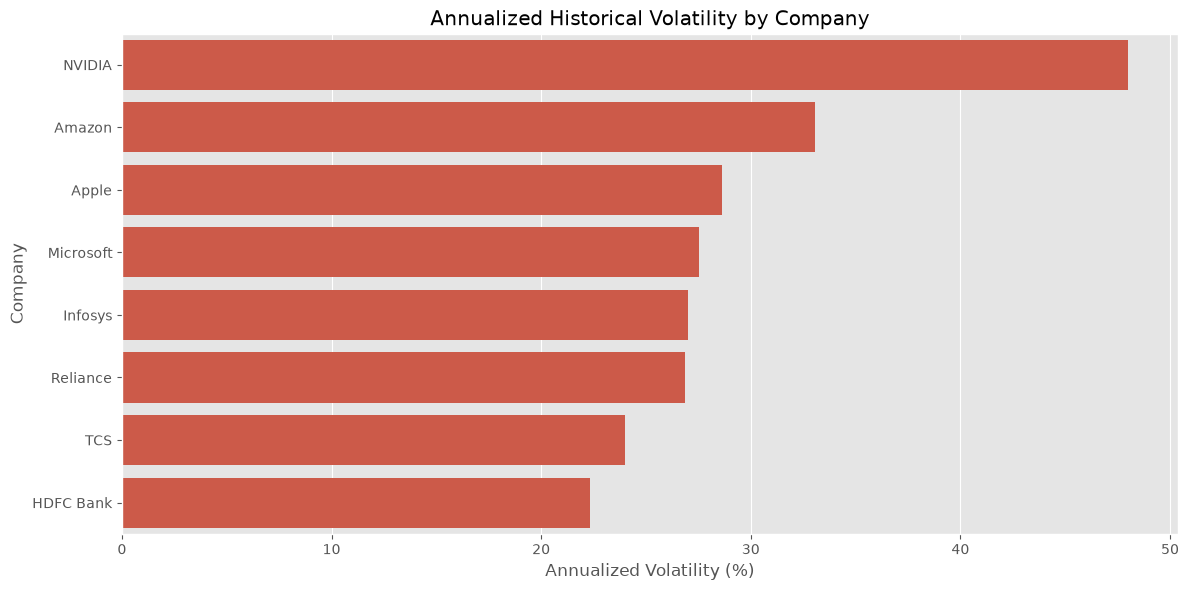

In [8]:
risk_metrics = []

for company, df in stock_data.items():
    df = df.sort_values("Date").dropna(subset=["Close"]).copy()
    df["Daily_Return"] = df["Close"].pct_change()
    daily_returns = df["Daily_Return"].dropna()

    if daily_returns.empty:
        continue

    first_close = df["Close"].iloc[0]
    last_close = df["Close"].iloc[-1]
    elapsed_days = (df["Date"].iloc[-1] - df["Date"].iloc[0]).days
    elapsed_years = elapsed_days / 365.25

    cumulative_return = ((last_close / first_close) - 1) * 100
    annualized_return = (
        ((last_close / first_close) ** (1 / elapsed_years) - 1) * 100
        if elapsed_years > 0 and first_close > 0 and last_close > 0
        else float("nan")
    )
    annualized_volatility = daily_returns.std() * (252 ** 0.5) * 100

    risk_metrics.append({
        "Company": company,
        "Cumulative Return (%)": cumulative_return,
        "Annualized Return (%)": annualized_return,
        "Annualized Volatility (%)": annualized_volatility
    })

risk_metrics_df = pd.DataFrame(risk_metrics).sort_values(
    "Annualized Volatility (%)", ascending=False
).reset_index(drop=True)

display(risk_metrics_df.round(2))

plt.figure(figsize=(12, 6))
sns.barplot(
    data=risk_metrics_df,
    x="Annualized Volatility (%)",
    y="Company"
)
plt.title("Annualized Historical Volatility by Company")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Company")
plt.tight_layout()
plt.show()


## Analysis 4 — Risk–Return Comparison

This scatter plot compares annualized historical return with annualized volatility for each company.

- **X-axis:** Annualized volatility (historical risk proxy)
- **Y-axis:** Annualized return
- **Each point:** One company

This is a descriptive comparison of historical data, not a guarantee of future performance. The measurement period and currencies differ across markets, so interpret the chart accordingly.


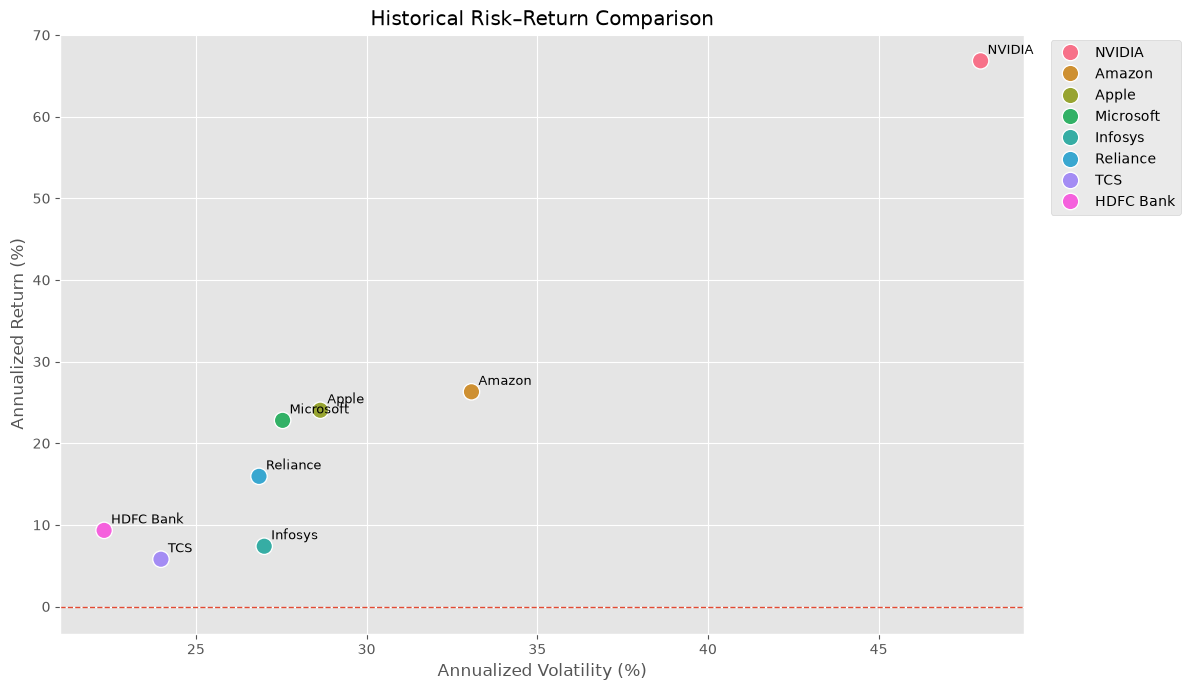

In [9]:
risk_return_df = risk_metrics_df.dropna(
    subset=["Annualized Return (%)", "Annualized Volatility (%)"]
).copy()

plt.figure(figsize=(12, 7))
sns.scatterplot(
    data=risk_return_df,
    x="Annualized Volatility (%)",
    y="Annualized Return (%)",
    hue="Company",
    s=140
)

for _, row in risk_return_df.iterrows():
    plt.annotate(
        row["Company"],
        (row["Annualized Volatility (%)"], row["Annualized Return (%)"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.axhline(0, linewidth=1, linestyle="--")
plt.title("Historical Risk–Return Comparison")
plt.xlabel("Annualized Volatility (%)")
plt.ylabel("Annualized Return (%)")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## Key Findings

Use the outputs above to summarize the results. The following cell generates a short, data-driven summary from the current CSV files; review it alongside the charts before drawing conclusions.


In [11]:
if not cumulative_returns_df.empty:
    best_return = cumulative_returns_df.iloc[0]
    lowest_return = cumulative_returns_df.iloc[-1]
    print(
        f"Highest cumulative return: {best_return['Company']} "
        f"({best_return['Cumulative Return (%)']:.2f}%)."
    )
    print(
        f"Lowest cumulative return: {lowest_return['Company']} "
        f"({lowest_return['Cumulative Return (%)']:.2f}%)."
    )

if not risk_metrics_df.empty:
    highest_volatility = risk_metrics_df.iloc[0]
    lowest_volatility = risk_metrics_df.iloc[-1]
    print(
        f"Highest annualized volatility: {highest_volatility['Company']} "
        f"({highest_volatility['Annualized Volatility (%)']:.2f}%)."
    )
    print(
        f"Lowest annualized volatility: {lowest_volatility['Company']} "
        f"({lowest_volatility['Annualized Volatility (%)']:.2f}%)."
    )

print(
    "\nInterpretation note: These are historical comparisons. "
    "They do not predict future returns or establish investment suitability."
)


Highest cumulative return: NVIDIA (42356.04%).
Lowest cumulative return: TCS (94.69%).
Highest annualized volatility: NVIDIA (47.99%).
Lowest annualized volatility: HDFC Bank (22.31%).

Interpretation note: These are historical comparisons. They do not predict future returns or establish investment suitability.
